# IFRS 17 en la práctica: modelo general (GMM) frente al régimen anterior

**Objetivo.** Aplicar el **modelo general de medición** de IFRS 17 a un grupo de contratos de vida riesgo y ver,
con números, qué cambia frente al régimen anterior (IFRS 4 con criterio contable local, como el PCEA en España)
y en qué se diferencia de **Solvencia II**.

**Producto.** Seguro temporal de fallecimiento a 10 años: 1.000 hombres de 40 años, capital de 100.000 €,
prima anual nivelada, caídas del 5 % anual y mortalidad de mejor estimación según la tabla del INE de 2024.

**Contenido**
1. Hipótesis y tarificación
2. Reconocimiento inicial: flujos de cumplimiento, ajuste por riesgo y **CSM**
3. Contratos **onerosos**: pérdida el primer día
4. Evolución del CSM: intereses, liberación y **cambio de hipótesis**
5. Nueva cuenta de resultados frente al régimen anterior
6. IFRS 17 frente a Solvencia II

### Qué cambia con IFRS 17

| | Régimen anterior (IFRS 4 / PCEA) | **IFRS 17** | Solvencia II |
|---|---|---|---|
| Objetivo | Contabilidad, con criterios locales muy distintos entre países | Contabilidad **comparable** entre aseguradoras | Solvencia (capital) |
| Ingresos | Primas emitidas o devengadas | **Ingresos de seguros** = servicio prestado en el periodo (sin componentes de inversión) | No aplica |
| Pasivo | Provisiones con **bases técnicas prudentes**, fijadas al emitir | **Flujos de cumplimiento** (mejor estimación descontada + **ajuste por riesgo**) **+ CSM** | **Mejor estimación + margen de riesgo** |
| Beneficio futuro esperado | Implícito en la prudencia de las bases; aflora según el patrón de provisiones | **CSM**: beneficio no devengado que se libera según el servicio | Se reconoce como fondos propios desde el inicio |
| Contratos onerosos | Solo si falla la prueba de adecuación de pasivos | Pérdida **inmediata** el primer día | Mejor estimación negativa o positiva, sin CSM |
| Tipos de descuento | Interés técnico fijo | Tipos **actuales**; el CSM acumula intereses al tipo bloqueado | Curva libre de riesgo de EIOPA |
| Cambios de hipótesis | Normalmente no se revisan las bases | Si afectan al servicio futuro, los **absorbe el CSM** | Impactan directamente en fondos propios |
| Agregación | Por producto o cartera | Carteras × **cohortes anuales** × rentabilidad (onerosos / sin riesgo de serlo / resto) | Líneas de negocio |

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from ifrs17 import (Basis, Contract, gmm_rollforward, initial_recognition, local_gaap,
                    price, project, solvency_ii_inception)

FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)
pd.set_option("display.float_format", lambda x: f"{x:,.0f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
ACC, ORANGE, GREY, RED = "#3E6470", "#D9822B", "#9AA5AD", "#B5473A"

## 1. Hipótesis y tarificación

In [2]:
raw = pd.read_csv(ROOT / "data" / "ine_mortality_lx.csv")
lx = raw[(raw.tabla_id == "INE_2024") & (raw.sexo == "H")].set_index("edad")["lx"]
qx = (1 - lx.shift(-1) / lx).dropna()

basis = Basis(qx, rate=0.03)                       # mejor estimación y tipo de descuento del 3 %
contract = Contract(age=40, term=10, n_policies=1_000, sum_insured=100_000,
                    maintenance=40, acquisition=150, lapse=0.05)
contract.premium = price(contract, basis, margin=0.25)   # tarifa con un 25 % de recargo sobre el coste
print(f"Prima anual de tarifa: {contract.premium:,.2f} € por póliza")
proj_table = (pd.DataFrame(project(contract, basis)).drop(columns="years")
              .set_index(pd.RangeIndex(1, 11, name="Año"))
              .rename(columns={"inforce": "Pólizas en vigor", "deaths": "Fallecimientos esperados",
                               "premiums": "Primas", "expenses": "Gastos", "acquisition": "Adquisición",
                               "claims": "Siniestros esperados"}))
proj_table.style.format({c: ("{:.2f}" if c == "Fallecimientos esperados" else "{:,.1f}" if c == "Pólizas en vigor"
                              else "{:,.0f}") for c in proj_table.columns})

Prima anual de tarifa: 232.57 € por póliza


,Pólizas en vigor,Fallecimientos esperados,Primas,Gastos,Adquisición,Siniestros esperados
Año,,,,,,
1,"1,000.0",0.85,"232,569","40,000","150,000","85,445"
2,949.2,0.94,"220,752","37,968",0,"93,897"
3,900.8,1.02,"209,507","36,033",0,"102,430"
4,854.8,1.00,"198,805","34,193",0,"99,810"
5,811.1,1.01,"188,644","32,445",0,"101,235"
6,769.6,1.06,"178,988","30,785",0,"105,659"
7,730.1,1.07,"169,805","29,205",0,"106,656"
8,692.6,1.11,"161,079","27,704",0,"110,658"
9,656.9,1.20,"152,781","26,277",0,"120,027"


## 2. Reconocimiento inicial

- **Flujos de cumplimiento (FCF)** = valor actual de las salidas (siniestros y gastos) menos el de las entradas
  (primas), más el **ajuste por riesgo no financiero (RA)**.
- El RA se calcula con la técnica del **nivel de confianza (75 %)**: la incertidumbre sobre el nivel de mortalidad
  se modeliza con un multiplicador lognormal (desviación del 10 %). IFRS 17 obliga a revelar ese nivel de confianza.
- Si los FCF son negativos (el grupo es rentable), el **CSM** los compensa: **no hay beneficio el primer día**.

In [3]:
init = initial_recognition(contract, basis)
init.to_frame("€")

,€
VA de flujos de salida y entrada,"-330,627"
Ajuste por riesgo (RA),"56,925"
Flujos de cumplimiento (FCF),"-273,702"
CSM,"273,702"
Pérdida reconocida el día 1,0


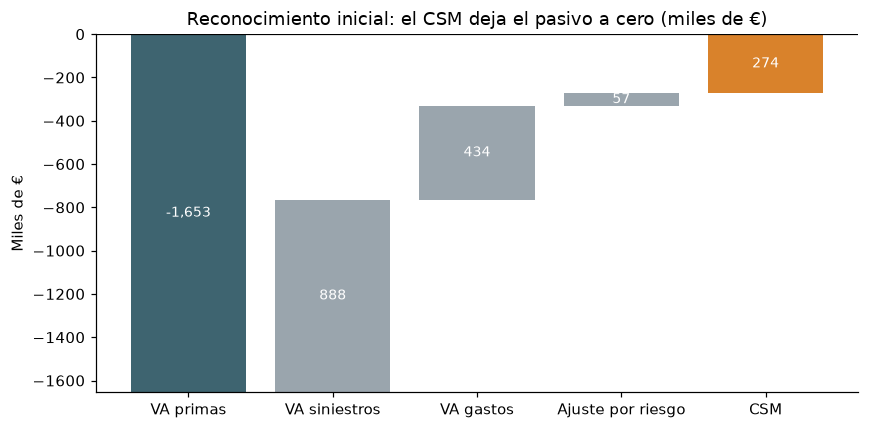

In [4]:
p = project(contract, basis)
v0, v1 = 1.03 ** -np.arange(10), 1.03 ** -np.arange(1, 11)
parts = {
    "VA primas": -(p["premiums"] * v0).sum(),
    "VA siniestros": (p["claims"] * v1).sum(),
    "VA gastos": ((p["expenses"] + p["acquisition"]) * v0).sum(),
    "Ajuste por riesgo": init["Ajuste por riesgo (RA)"],
    "CSM": init["CSM"],
}
fig, ax = plt.subplots(figsize=(8, 4))
cum = 0
for k, val in parts.items():
    color = ACC if k == "VA primas" else (ORANGE if k == "CSM" else GREY)
    ax.bar(k, val / 1e3, bottom=cum / 1e3, color=color)
    ax.text(k, (cum + val / 2) / 1e3, f"{val / 1e3:,.0f}", ha="center", va="center", color="white", fontsize=9)
    cum += val
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Reconocimiento inicial: el CSM deja el pasivo a cero (miles de €)", ylabel="Miles de €")
plt.tight_layout(); plt.savefig(FIG / "reconocimiento_inicial.png"); plt.show()

## 3. Contratos onerosos

Si la tarifa es demasiado baja (aquí, un 10 % **por debajo** del coste esperado), los flujos de cumplimiento son
positivos. IFRS 17 obliga a reconocer **toda la pérdida esperada el primer día** (componente de pérdida), separada
y visible. En el régimen anterior la pérdida no se identifica como tal: el año 1 muestra un resultado negativo que se
confunde con los gastos de adquisición y la dotación de la provisión (también aparece en el grupo rentable), y el
resto se va acumulando en los años siguientes, salvo que falle la prueba de adecuación de pasivos.

In [5]:
onerous = Contract(**{**contract.__dict__, "premium": price(contract, basis, margin=-0.10)})
init_on = initial_recognition(onerous, basis)
loc_on = local_gaap(onerous, basis)
comparison_on = pd.DataFrame({
    "IFRS 17 (pérdida del día 1)": [init_on["Pérdida reconocida el día 1"]],
    "Régimen anterior: resultado del año 1": [loc_on["Resultado régimen anterior"].iloc[0]],
    "Régimen anterior: resultado acumulado de los 10 años": [loc_on["Resultado régimen anterior"].sum()],
}, index=["Grupo oneroso"]).T
comparison_on

,Grupo oneroso
IFRS 17 (pérdida del día 1),"189,047"
Régimen anterior: resultado del año 1,"-159,870"
Régimen anterior: resultado acumulado de los 10 años,"-177,734"


## 4. Evolución del CSM

Dos sucesos durante la vida del grupo:
- **Año 2**: la siniestralidad real es un 10 % superior a la esperada. Es **servicio pasado**, así que va directamente a resultados.
- **Final del año 3**: la mortalidad esperada para el futuro sube un 20 %. Es **servicio futuro**, así que **lo absorbe el CSM**
  (medido al tipo bloqueado) y el beneficio se reparte en los años que quedan.

Cada año, el CSM acumula intereses al tipo bloqueado y se libera en proporción a las **unidades de cobertura**
(capital asegurado en vigor).

In [6]:
CHANGE, SHOCK = (2, 1.2), {1: 1.1}
gmm = gmm_rollforward(contract, basis, change=CHANGE, claims_shock=SHOCK)
loc = local_gaap(contract, basis, change=CHANGE, claims_shock=SHOCK)

csm_open = pd.Series([init["CSM"]] + gmm["CSM (final)"].iloc[:-1].tolist(), index=gmm.index)
csm_table = pd.DataFrame({
    "CSM inicial": csm_open,
    "Intereses (tipo bloqueado)": gmm["Intereses del CSM"],
    "Ajuste por servicio futuro": gmm["Ajuste del CSM por servicio futuro"],
    "Liberación a resultados": -gmm["Liberación del CSM"],
    "CSM final": gmm["CSM (final)"],
})
csm_table

,CSM inicial,Intereses (tipo bloqueado),Ajuste por servicio futuro,Liberación a resultados,CSM final
Año,,,,,
1,"273,702","8,211",-0,"-35,291","246,622"
2,"246,622","7,399",-0,"-34,503","219,518"
3,"219,518","6,586","-144,771","-12,140","69,193"
4,"69,193","2,076",-0,"-11,866","59,403"
5,"59,403","1,782",-0,"-11,594","49,591"
6,"49,591","1,488",-0,"-11,328","39,751"
7,"39,751","1,193",-0,"-11,066","29,877"
8,"29,877",896,-0,"-10,809","19,964"
9,"19,964",599,-0,"-10,556","10,007"


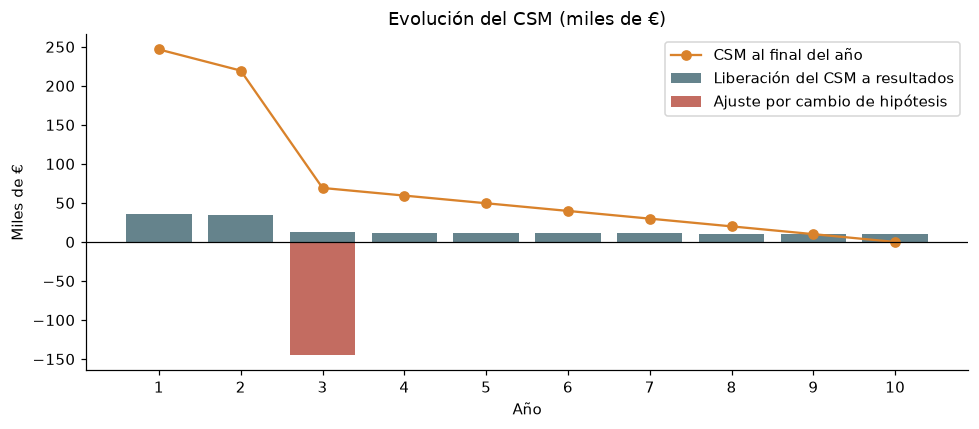

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
years = gmm.index
ax.plot(years, gmm["CSM (final)"] / 1e3, marker="o", color=ORANGE, label="CSM al final del año")
ax.bar(years, gmm["Liberación del CSM"] / 1e3, color=ACC, alpha=0.8, label="Liberación del CSM a resultados")
ax.bar(years, gmm["Ajuste del CSM por servicio futuro"] / 1e3, color=RED, alpha=0.8, label="Ajuste por cambio de hipótesis")
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Evolución del CSM (miles de €)", xlabel="Año", ylabel="Miles de €", xticks=years)
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "csm.png"); plt.show()

## 5. Cuenta de resultados: IFRS 17 frente al régimen anterior

Con IFRS 17, los **ingresos de seguros** ya no son las primas cobradas, sino el servicio prestado en el año:
siniestros y gastos esperados, más la liberación del RA y del CSM, más la recuperación de los gastos de adquisición.

In [8]:
pl = pd.DataFrame({
    "Ingresos (régimen anterior: primas)": loc["Primas emitidas (ingreso)"],
    "Ingresos de seguros IFRS 17": gmm["Ingresos de seguros"],
    "Resultado del servicio de seguros": gmm["Resultado del servicio de seguros"],
    "Resultado financiero neto": gmm["Ingresos financieros"] - gmm["Gastos financieros de seguros"],
    "Resultado IFRS 17": gmm["Resultado IFRS 17"],
    "Resultado régimen anterior": loc["Resultado régimen anterior"],
})
pl.loc["Total"] = pl.sum()
pl

,Ingresos (régimen anterior: primas),Ingresos de seguros IFRS 17,Resultado del servicio de seguros,Resultado financiero neto,Resultado IFRS 17,Resultado régimen anterior
Año,,,,,,
1,"232,569","183,297","39,074","1,708","40,782","-92,797"
2,"220,752","188,627","29,549","2,818","32,367","50,089"
3,"209,507","172,632","17,253","3,656","20,908","60,617"
4,"198,805","187,988","17,971","4,389","22,359","40,748"
5,"188,600","187,109","17,986","4,876","22,862","39,986"
6,"178,902","190,197","18,246","5,370","23,616","38,372"
7,"169,677","189,046","18,263","5,871","24,134","36,711"
8,"160,910","191,855","18,525","6,379","24,904","34,259"
9,"152,572","201,631","19,219","6,895","26,114","30,454"


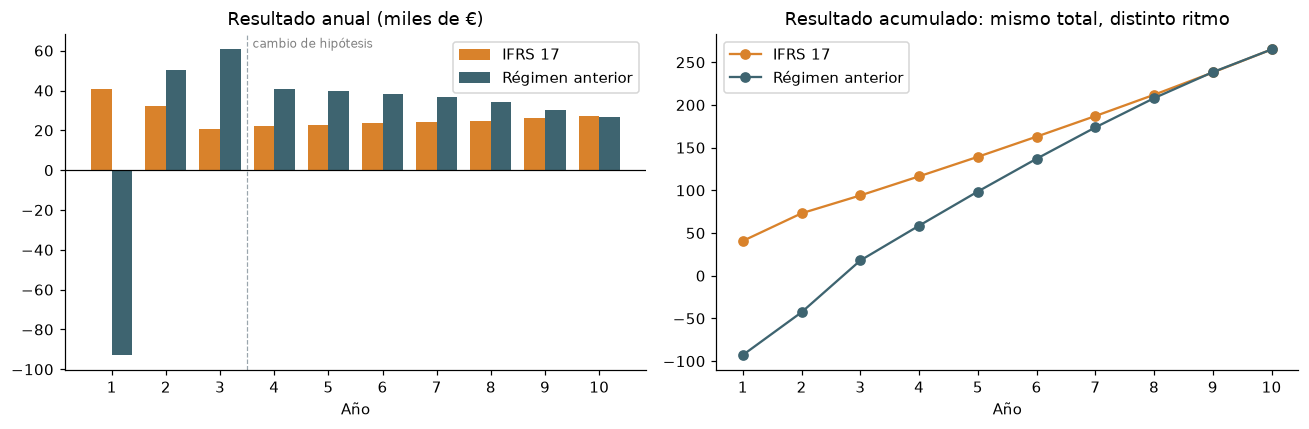

Beneficio total IFRS 17: 265,014 € · régimen anterior: 265,014 €


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
w = 0.38
axes[0].bar(years - w / 2, gmm["Resultado IFRS 17"] / 1e3, w, color=ORANGE, label="IFRS 17")
axes[0].bar(years + w / 2, loc["Resultado régimen anterior"] / 1e3, w, color=ACC, label="Régimen anterior")
axes[0].axhline(0, color="black", lw=0.8)
axes[0].axvline(3.5, color=GREY, ls="--", lw=0.8)
axes[0].text(3.6, axes[0].get_ylim()[1] * 0.9, "cambio de hipótesis", fontsize=8, color="grey")
axes[0].set(title="Resultado anual (miles de €)", xlabel="Año", xticks=years)
axes[0].legend()

axes[1].plot(years, gmm["Resultado IFRS 17"].cumsum() / 1e3, marker="o", color=ORANGE, label="IFRS 17")
axes[1].plot(years, loc["Resultado régimen anterior"].cumsum() / 1e3, marker="o", color=ACC, label="Régimen anterior")
axes[1].set(title="Resultado acumulado: mismo total, distinto ritmo", xlabel="Año", xticks=years)
axes[1].legend()
plt.tight_layout(); plt.savefig(FIG / "resultados.png"); plt.show()
print(f"Beneficio total IFRS 17: {gmm['Resultado IFRS 17'].sum():,.0f} € · "
      f"régimen anterior: {loc['Resultado régimen anterior'].sum():,.0f} €")

## 6. IFRS 17 frente a Solvencia II

Ambos parten de la **mejor estimación** de los flujos, pero:
- Solvencia II añade un **margen de riesgo** por coste de capital (6 % del SCR proyectado) y **no tiene CSM**: el beneficio
  futuro esperado cuenta como fondos propios desde el primer día.
- IFRS 17 añade un **ajuste por riesgo** (aquí, con un nivel de confianza del 75 %) y guarda el beneficio futuro en el CSM.

In [10]:
s2 = solvency_ii_inception(contract, basis)
side = pd.DataFrame({
    "IFRS 17": [init["VA de flujos de salida y entrada"], init["Ajuste por riesgo (RA)"], init["CSM"],
                init["VA de flujos de salida y entrada"] + init["Ajuste por riesgo (RA)"] + init["CSM"]],
    "Solvencia II": [s2["Mejor estimación (BEL)"], s2["Margen de riesgo (RM)"], 0.0, s2["Provisiones técnicas (BEL + RM)"]],
}, index=["Mejor estimación", "Margen por riesgo (RA / RM)", "CSM", "Pasivo total"])
side

,IFRS 17,Solvencia II
Mejor estimación,"-330,627","-330,627"
Margen por riesgo (RA / RM),"56,925","43,011"
CSM,"273,702",0
Pasivo total,0,"-287,616"


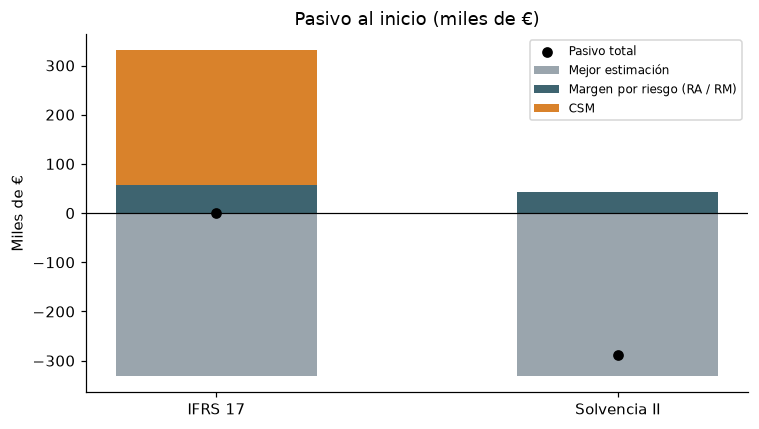

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
labels = ["Mejor estimación", "Margen por riesgo (RA / RM)", "CSM"]
colors = [GREY, ACC, ORANGE]
for j, col in enumerate(side.columns):
    pos, neg = 0, 0
    for lab, colr in zip(labels, colors):
        val = side.loc[lab, col] / 1e3
        base = pos if val >= 0 else neg
        ax.bar(j, val, bottom=base, color=colr, label=lab if j == 0 else None, width=0.5)
        if val >= 0:
            pos += val
        else:
            neg += val
    ax.scatter(j, side.loc["Pasivo total", col] / 1e3, color="black", zorder=3, label="Pasivo total" if j == 0 else None)
ax.set_xticks([0, 1], side.columns)
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Pasivo al inicio (miles de €)", ylabel="Miles de €")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(FIG / "ifrs17_vs_solvencia2.png"); plt.show()

## Conclusiones

1. **Mismo beneficio total, distinto ritmo.** Con IFRS 17, el beneficio aflora de forma estable, según el servicio
   prestado. En el régimen anterior, el primer año muestra pérdidas (gastos de adquisición y dotación de la provisión)
   y el perfil depende de lo prudentes que sean las bases técnicas.
2. **El CSM amortigua los cambios de hipótesis.** Una subida del 20 % de la mortalidad esperada reduce el CSM en lugar
   de llevarse el resultado de un año. Los desvíos del servicio pasado (año 2) sí van directos a resultados.
3. **Los contratos onerosos se ven desde el primer día.** IFRS 17 obliga a reconocer la pérdida al emitir, lo que hace
   visible una mala tarificación.
4. **IFRS 17 y Solvencia II comparten la mejor estimación**, pero el beneficio futuro es CSM (pasivo) en IFRS 17 y
   fondos propios en Solvencia II.

**Simplificaciones:** tipo de descuento plano y sin cambios (no hay OCI ni efecto de tipos), un solo grupo de
contratos, sin reaseguro y RA solo por riesgo de mortalidad.